# Пункт 1

Загрузим записи матчей из `NHL-playoffs-2026.xlsx` в таблицу `events`. Одна строка здесь — одно событие: бросок, гол, вбрасывание, удаление и т. д.

В первой ячейке указан полный путь к Excel. Если файл лежит в другой папке, нужно заменить этот путь. Ячейки запускаем сверху вниз в ядре Python 3.

Команды `%pip` устанавливают нужные библиотеки. Обычно их достаточно выполнить один раз.

Первый столбец Excel содержит сохранённые номера строк. Поэтому читаем его как индекс через `index_col=0`. Без этого в таблице появится лишнее поле `Unnamed: 0`.

Берём первый лист книги (`sheet_name=0`). Для чтения `.xlsx` используем `openpyxl`.

In [1]:
%pip install pandas openpyxl
import pandas as pd

events = pd.read_excel(
    r"D:\1 РЭШ\1 Модуль\Анализ данных в Python\Final Exam\NHL-playoffs-2026.xlsx", # Красным выделил путь до файла 
    sheet_name=0,
    index_col=0,
    engine="openpyxl",
)


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Посмотрим размер таблицы. `shape` возвращает число строк и столбцов.

In [3]:
events.shape

(29710, 38)

Выведем первые десять событий и пять полей: дату, команды, оставшееся время и тип события. В `.iloc` указываются позиции строк и столбцов; отсчёт начинается с нуля.

In [4]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Загрузились **29 710 событий и 38 полей**. Первые строки соответствуют примеру в условии. Дальше будем работать с этой таблицей.

# Пункт 2

Теперь соберём по одной строке на матч. Объединим события по `Game ID`, возьмём дату и названия команд, а для итогового счёта — максимальные значения накопленных голов. Складывать счёт по событиям нельзя: одна шайба повторяется во многих строках.

По последнему номеру периода определим, понадобились ли овертаймы. Если периодов три, запишем `Final`; если четыре — `Final/OT`; если пять — `Final/2OT`. Идентификатор матча оставим индексом таблицы `games`.

In [5]:
games = events.groupby("Game ID").agg({
    "Date": "first",
    "Away Team": "first",
    "Home Team": "first",
    "Cumulated Away Score": "max",
    "Cumulated Home Score": "max",
    "Period": "max",
})

games = games.rename(columns={
    "Cumulated Away Score": "Away Score",
    "Cumulated Home Score": "Home Score",
})

overtimes = games["Period"] - 3

games["Outcome"] = "Final"
games.loc[overtimes == 1, "Outcome"] = "Final/OT"
games.loc[overtimes > 1, "Outcome"] = (
    "Final/" + overtimes[overtimes > 1].astype(str) + "OT"
)

games = games.drop(columns="Period")

games.head()

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,Final/OT


Проверим, какие столбцы получились. `Game ID` в этот список не входит, потому что используется как индекс.

In [6]:
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')

Для проверки посмотрим последние пять матчей: команды, итоговый счёт и овертаймы.

In [7]:
games[["Home Team", "Away Score", "Home Score", "Outcome"]].tail()

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


В `games` получилось **82 матча**. На этом шаге у каждого матча шесть показателей.

# Пункт 3

Напишем `gameInfo(gameId)`, чтобы каждый раз не собирать описание матча вручную. Функция найдёт строку по `Game ID` и вернёт команды, счёт, результат и дату. Сначала указываем хозяев, затем гостей.

In [8]:
def gameInfo(gameId):
    """Возвращает команды, счёт, результат и дату матча по Game ID."""
    game = games.loc[gameId]
    return (
        f"{game['Home Team']} - {game['Away Team']} "
        f"({game['Home Score']} - {game['Away Score']}, "
        f"{game['Outcome']}, {game['Date']})"
    )

Проверим функцию на первом и последнем идентификаторах матчей.

In [9]:
gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [10]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

Функция возвращает готовую строку. Её можно использовать в списках матчей и подписях к рисункам.

# Пункт 4

Общее число голов за матч — это голы хозяев плюс голы гостей. Сохраним сумму в `Total Score`. В тексте задания встречается название `matches`, но продолжим использовать уже созданную таблицу `games`.

In [11]:
games["Total Score"] = games["Away Score"] + games["Home Score"]

games[["Away Score", "Home Score", "Total Score"]].head()

,Away Score,Home Score,Total Score
Game ID,,,
2025030111,3,4,7
2025030112,4,2,6
2025030113,3,1,4
2025030114,6,1,7
2025030115,2,1,3


С помощью `.describe()` получим число матчей, среднее, стандартное отклонение, минимум, максимум и квартили. Строка `50%` — медиана. Для удобства округлим вывод до трёх знаков.

In [12]:
games["Total Score"].describe().round(3)

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

В среднем за матч забивали **5,927 шайбы**, медиана — **6**. Самый низкий результат — **1 шайба**, самый высокий — **15**. Стандартное отклонение равно **2,260**, а первый и третий квартили — **5** и **7**.

# Пункт 5

Построим график общего числа голов. Для этого понадобятся `matplotlib` и `seaborn`; следующая ячейка установит их, если они ещё не установлены. Функция площадки из `rink.py` уже включена в ноутбук и пригодится ниже.

In [13]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.0)

Число голов принимает целые значения, поэтому используем `countplot()`. Высота столбца покажет, сколько матчей завершилось с таким общим счётом. На оси оставим и значения, которые ни разу не встретились.

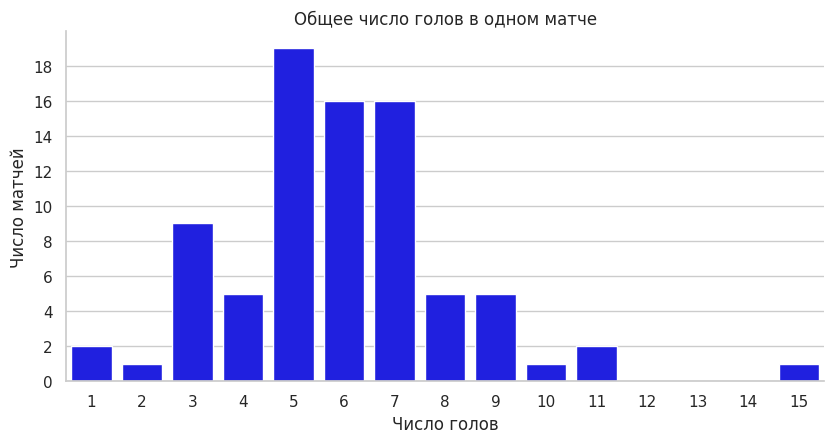

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))

sns.countplot(
    data=games,
    x="Total Score",
    order=range(games["Total Score"].min(), games["Total Score"].max() + 1),
    color="blue",
    ax=ax,
)

ax.set_title("Общее число голов в одном матче")
ax.set_xlabel("Число голов")
ax.set_ylabel("Число матчей")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

Чаще всего забивали **5 шайб**: таких матчей было **19**. Всего **51 из 82 матчей (62,2%)** завершился с 5–7 шайбами. Матч с 15 голами сильно выделяется; справа виден хвост из редких высоких результатов.

# Пункт 6

Найдём минимум и максимум `Total Score`, затем выведем все матчи с этими значениями. Здесь важно сохранить все совпадения: минимальный результат встречается дважды.

In [16]:
min_total_score = games["Total Score"].min()
least_game_ids = games.index[games["Total Score"] == min_total_score]
least_scoring_games = [gameInfo(game_id) for game_id in least_game_ids]

least_scoring_games

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [17]:
max_total_score = games["Total Score"].max()
most_game_ids = games.index[games["Total Score"] == max_total_score]
most_scoring_games = [gameInfo(game_id) for game_id in most_game_ids]

most_scoring_games

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

В двух самых нерезультативных играх забили по **одной шайбе**. Самым результативным стал матч Colorado Avalanche — Minnesota Wild со счётом **9:6**, то есть **15 шайбами** на две команды.

# Пункт 7

Посчитаем игроков, которые хотя бы раз появились на льду в каждом матче. Возьмём шесть полей состава и поле вратаря для обеих команд. Повторные появления одного игрока учитываем один раз, пустые значения пропускаем.

Сначала считаем составы команд отдельно, затем складываем результаты. Так совпадение имён у соперников не уменьшит число участников. В условии поля гостей перечислены дважды; для второй команды берём поля хозяев.

In [18]:
player_counts_by_side = pd.DataFrame(index=games.index)
all_lineup_columns = []

for side in ["Away", "Home"]:
    lineup_columns = [
        f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)
    ] + [f"{side} Team's Goalie"]
    all_lineup_columns.extend(lineup_columns)

    players_long = events[["Game ID"] + lineup_columns].melt(
        id_vars="Game ID",
        value_name="Player",
    )

    # Повторные появления одного игрока и пропуски не увеличивают счётчик.
    player_counts_by_side[side] = (
        players_long.groupby("Game ID")["Player"].nunique()
    )

players_per_game = pd.DataFrame({
    "Game Info": [gameInfo(game_id) for game_id in games.index],
    "Player Count": player_counts_by_side.sum(axis=1),
}, index=games.index)

max_players_games = players_per_game.loc[
    players_per_game["Player Count"] == players_per_game["Player Count"].max()
]

max_players_games

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Максимум получился в матче **2025030216**: **40 игроков**, по 20 у каждой команды, включая вратарей. В примере PDF указано 41. Такое число получается, если добавить к уникальным именам ещё и `NaN`. Пустая ячейка игроком не является, поэтому оставляем 40. Ниже показана проверка.

In [19]:
max_players_game_id = max_players_games.index[0]
lineup_values = events.loc[
    events["Game ID"] == max_players_game_id,
    all_lineup_columns,
].to_numpy().ravel()

unique_lineup_values = pd.unique(lineup_values)

pd.Series({
    "Игроков гостей": player_counts_by_side.loc[max_players_game_id, "Away"],
    "Игроков хозяев": player_counts_by_side.loc[max_players_game_id, "Home"],
    "Реальных игроков всего": pd.Series(unique_lineup_values).nunique(),
    "Уникальных значений вместе с NaN": len(unique_lineup_values),
}, name="Проверка состава матча")

Игроков гостей                      20
Игроков хозяев                      20
Реальных игроков всего              40
Уникальных значений вместе с NaN    41
Name: Проверка состава матча, dtype: int64

# Пункт 8

Для событий `shot-on-goal`, `goal` и `missed-shot` посчитаем расстояние до ближайшей точки створа. Голы и броски, остановленные вратарём, относятся к точным; промахи — к неточным.

Сначала определим атакуемые ворота. Если хозяева защищают левые, они бросают в правые, а гости — в левые. При защите правых ворот направления меняются.

| Сторона ворот хозяев | Кто бросает | X атакуемых ворот |
| --- | --- | --- |
| left | Хозяева | 89 |
| left | Гости | −89 |
| right | Хозяева | −89 |
| right | Гости | 89 |

Створ занимает отрезок от `(X, -3)` до `(X, 3)`. Ближайшая точка имеет координату $y_* = \min(3,\max(-3,y))$. Тогда

$$d=\sqrt{(x-X)^2+(y-y_*)^2}.$$

Так учитывается ширина ворот: расстояние считаем до створа, а не до его центра. Единицы измерения — футы.

In [20]:
shot_types = ["shot-on-goal", "goal", "missed-shot"]
shots = events.loc[events["Play Type"].isin(shot_types)].copy()

is_home_shot = shots["Team Making the Play"] == shots["Home Team"]
home_defends_left = shots["Home Team's Defending Side"] == "left"

shots["Goal X"] = np.where(is_home_shot == home_defends_left, 89, -89)

x = shots["X Coordinate on the Ice Rink"]
y = shots["Y Coordinate on the Ice Rink"]
closest_goal_y = y.clip(lower=-3, upper=3)

shots["Shot Length"] = np.hypot(
    x - shots["Goal X"],
    y - closest_goal_y,
)

events["Shot Length"] = np.nan
events.loc[shots.index, "Shot Length"] = shots["Shot Length"]

events.loc[
    events["Play Type"].isin(shot_types),
    ["Game ID", "Play Type", "Shot Length"],
].round(3)

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


На дополнительной схеме ниже показан смысл расчёта. `P` — условная точка броска `(69, 22)`, `Q` — ближайшая точка створа `(89, 3)`. Эти обозначения добавлены для пояснения и не являются отдельными событиями из данных. Площадку рисует функция из приложенного `rink.py`.

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_rink(annotations=False):
    plt.gcf().gca().add_artist(plt.Rectangle((-103,-44.5), 206, 89,
                                             linewidth=0,
                                             facecolor='whitesmoke',
                                             zorder=-2))

    line, = plt.plot([0,0], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='firebrick', zorder=-1)
    plt.scatter([0,0,0,0,0,0,0,0,0,0,0,0], [6,12,18,24,30,36,-6,-12,-18,-24,-30,-36], s=3, color='w', zorder=-1)
    for x in [-25, 25]:
        plt.plot([x,x], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='royalblue', zorder=-1)
    for x in [-25-64, 25+64]:
        plt.plot([x,x], [-36.75,36.75], linewidth=1, solid_capstyle='butt', color='firebrick', zorder=-1)


    plt.gcf().gca().add_artist(plt.Circle((0,0), 15, fill=False,
                                          linewidth=1, color='royalblue', zorder=-1))
    for x in [69, -69]:
        for y in [22, -22]:
            plt.gcf().gca().add_artist(plt.Circle((x,y), 15, fill=False,
                                                  linewidth=1, color='firebrick', zorder=-1))
            for dx in [-1,1]:
                for dy in [-1,1]:
                    plt.plot([x+dx*3,x+dx*1,x+dx*1], [y+dy*0.5,y+dy*0.5,y+dy*2], linewidth=1, color='firebrick', zorder=-1)
                    plt.plot([x+dx*1.5,x+dx*1.5], [y+dy*14.93,y+dy*16], linewidth=1, color='firebrick', zorder=-1)


    plt.scatter([0], [0], s=4, color='royalblue', zorder=-1)
    plt.scatter([69,69,-69,-69,-20,-20,20,20], [22,-22,22,-22,22,-22,22,-22], s=6, color='firebrick', zorder=-1)


    plt.gcf().gca().add_artist(mpatches.Arc((0,-42.5), 10, 10, angle=0, theta1=0, theta2=180,
                                            color='firebrick', zorder=-1))


    for xscale,thoffset in [(-1,0), (1,180)]:
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [-4,-4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [4,4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [-4,-3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [4,3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.gcf().gca().add_artist(mpatches.Arc((xscale*(25+64),0), 12, 12,
                                                angle=0, theta1=-41.75+thoffset, theta2=41.75+thoffset,
                                                color='firebrick', zorder=-1))
        plt.plot([xscale*(25+64),xscale*(25+64+10/3),xscale*(25+64+10/3),xscale*(25+64)], [-3,-3,3,3], linewidth=1, color='firebrick', zorder=-1)

    for dx in [-1,1]:
        for dy in [-1,1]:
            plt.plot([dx*(25+64),dx*(100)], [dy*11,dy*14], linewidth=1, color='firebrick', zorder=-1)


    plt.plot([-100+28,100-28], [42.5,42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100+28,100-28], [-42.5,-42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100,-100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    plt.plot([100,100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    # Corner arcs
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,42.5-28), 2*28, 2*28, angle=0, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,42.5-28), 2*28, 2*28, angle=90, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,-42.5+28), 2*28, 2*28, angle=180, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,-42.5+28), 2*28, 2*28, angle=-90, theta1=0, theta2=90,
                                            color='black', zorder=-1))

    if annotations:
        plt.annotate("$0{,}0$", (2,2), ha='left', va='top')
        plt.annotate("${-}20{,}22$", (-18,24), ha='left', va='top')
        plt.annotate("$69{,}{-}22$", (69,-24), ha='center', va='top')
        plt.annotate("$89{,}0$", (87,0), ha='right', va='center')
        plt.annotate("${-}89{,}0$", (-87,0), ha='left', va='center')

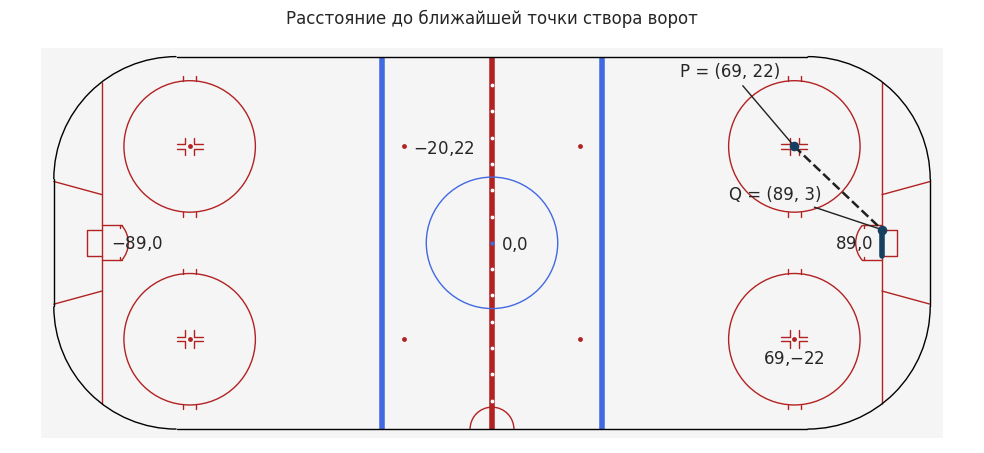

In [22]:
fig = plt.figure(figsize=(10, 4.7))
plot_rink(annotations=True)

plt.plot([89, 89], [-3, 3], color="#173f5f", linewidth=4, zorder=4)
plt.plot([69, 89], [22, 3], color="#202020", linestyle="--", linewidth=1.8)
plt.scatter([69, 89], [22, 3], color="#173f5f", s=35, zorder=5)
plt.annotate("P = (69, 22)", (69, 22), xytext=(43, 38),
             arrowprops={"arrowstyle": "-", "color": "#202020"})
plt.annotate("Q = (89, 3)", (89, 3), xytext=(54, 10),
             arrowprops={"arrowstyle": "-", "color": "#202020"})

plt.title("Расстояние до ближайшей точки створа ворот", pad=14)
plt.axis("equal")
plt.axis("off")
fig.tight_layout()
plt.show()

Расстояния получены для **7 266 бросков** и сохранены в `Shot Length`. У остальных событий это поле пустое. Первые значения — **12,207; 12,000; 29,411; 62,169; 52,924 фута** — совпадают с примером задания. В расчётах используются полные значения, без округления.

# Пункт 9

Сравним расстояния точных и неточных бросков. В группах разное число наблюдений — **4 623** и **2 643**, поэтому абсолютные частоты здесь неудобны.

Построим две гистограммы плотности с общими интервалами по 5 футов. Параметр `common_norm=False` нормирует каждую группу отдельно: площадь каждой гистограммы равна единице. Так можно сравнивать форму распределений.

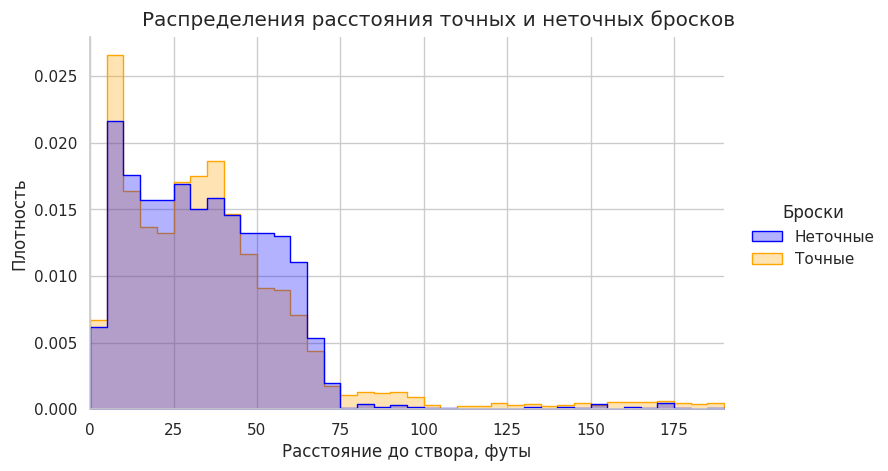

In [23]:
shots["Shot"] = np.where(shots["Play Type"] == "missed-shot", "Неточные", "Точные")

bin_width = 5
upper_distance = int(np.ceil(shots["Shot Length"].max() / bin_width) * bin_width)
shot_bins = np.arange(0, upper_distance + bin_width, bin_width)

distance_plot = sns.displot(
    data=shots,
    x="Shot Length",
    hue="Shot",
    hue_order=["Неточные", "Точные"],
    bins=shot_bins,
    common_bins=True,
    stat="density",
    common_norm=False,
    element="step",
    fill=True,
    alpha=0.30,
    palette={"Неточные": "blue", "Точные": "orange"},
    height=4.6,
    aspect=1.65,
)

distance_plot.set_axis_labels("Расстояние до створа, футы", "Плотность")
distance_plot.set(xlim=(0, upper_distance))
distance_plot.legend.set_title("Броски")
distance_plot.figure.suptitle("Распределения расстояния точных и неточных бросков", y=1.02)
plt.show()

In [24]:
distance_summary = shots.groupby("Shot")["Shot Length"].agg(["count", "mean", "median"])
distance_summary.round(3)

,count,mean,median
Shot,,,
Неточные,2643,34.014,32.249
Точные,4623,36.207,31.828


Отдельно посмотрим, сколько было бросков с расстояния больше 100 футов. Это поможет разобраться с длинным хвостом справа.

In [25]:
shots.loc[shots["Shot Length"] > 100].groupby(["Shot", "Play Type"]).size().rename("Count")

Shot      Play Type   
Неточные  missed-shot      23
Точные    goal             17
          shot-on-goal    143
Name: Count, dtype: int64

Большая часть обеих групп находится примерно в диапазоне **5–65 футов**. Медианы почти одинаковы: **31,828 фута** у точных и **32,249** у неточных. Среднее у точных выше — **36,207** против **34,014 фута**, поскольку у них заметнее длинный хвост.

С расстояния больше 100 футов было **160 точных бросков** и **23 промаха** — примерно **3,46%** и **0,87%** своих групп. Из 160 точных бросков 143 остановил вратарь, ещё 17 закончились голом.

Возможное объяснение — дальние выносы или броски из своей зоны, направленные в створ. Иногда это могут быть и попытки попасть в пустые ворота. По одной гистограмме установить причину каждого эпизода нельзя, но видно, что хвост не сводится только к голам.

# Пункт 10

Теперь для каждой команды в каждом матче найдём долю точных бросков среди незаблокированных:

$$\frac{N(\text{shot-on-goal})+N(\text{goal})}{N(\text{shot-on-goal})+N(\text{goal})+N(\text{missed-shot})}.$$

Голы входят в числитель, заблокированные попытки в этот расчёт не входят. Сгруппируем события по матчу, команде и типу; если какого-то типа не было, поставим ноль.

In [26]:
numshots = (
    shots.groupby(["Game ID", "Team Making the Play", "Play Type"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=shot_types, fill_value=0)
)
numshots.columns.name = None

numshots["Shots on Goal"] = numshots["shot-on-goal"] + numshots["goal"]
numshots["Unblocked Shots"] = numshots[shot_types].sum(axis=1)
numshots["Share of Shots on Goal"] = (
    numshots["Shots on Goal"] / numshots["Unblocked Shots"]
)

numshots["Share of Shots on Goal"].round(3)

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Получилось **164 строки** — по две команды на каждый из 82 матчей. Посмотрим на разброс долей и на общий результат по всем броскам.

In [27]:
numshots["Share of Shots on Goal"].describe().round(3)

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

In [28]:
overall_shot_share = numshots["Shots on Goal"].sum() / numshots["Unblocked Shots"].sum()
overall_shot_share

np.float64(0.6362510322047894)

Доли по отдельным матчам менялись от **35,3% до 86,0%**. Среднее и медиана близки к **63,9%**: обычно в створ попадало около двух третей незаблокированных попыток.

Во всей выборке точными были **4 623 из 7 266 бросков (63,6%)**. Общая доля немного отличается от среднего по матчам, потому что число бросков в играх разное. Этот показатель говорит о попадании в створ; долю голов нужно оценивать отдельно.

# Пункт 11

Найдём среднюю долю точных бросков каждой команды, а затем выведем по пять лучших и худших значений. Усредняем именно доли за матч, поэтому каждая игра получает одинаковый вес. Округлять будем после ранжирования.

In [29]:
avgnumshots = (
    numshots["Share of Shots on Goal"]
    .groupby(level="Team Making the Play")
    .mean()
)

avgnumshots.nlargest(5).round(3)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [30]:
avgnumshots.nsmallest(5).round(3)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Лидер — **Edmonton Oilers (около 70,6%)**, самое низкое значение у **Pittsburgh Penguins (около 55,4%)**. Разница — примерно **15,2 процентного пункта**. Команды провели разное число матчей и играли с разными соперниками, поэтому рейтинг относится именно к этой выборке.

# Пункт 12

Посчитаем среднее число бросков в створ и голов за матч для каждой команды. В `numshots` уже есть все пары «матч — команда», в том числе игры без голов. Усредним `Shots on Goal` и `goal`, а столбцы результата назовём `Shot` и `Goal`.

In [31]:
avgshots = (
    numshots.groupby(level="Team Making the Play")[["Shots on Goal", "goal"]]
    .mean()
    .rename(columns={"Shots on Goal": "Shot", "goal": "Goal"})
)

avgshots.round(3)

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Получены средние для всех **16 команд**. Больше всех бросков в створ за матч у **Colorado Avalanche (32,154)**, а голов — у **Minnesota Wild (3,727)**. Лидеры по этим двум показателям различаются.

# Пункт 13

Изобразим командные средние на регрессионной диаграмме. Каждая точка — команда: по горизонтали число бросков в створ за матч, по вертикали — число голов.

Линия показывает общую линейную связь, полупрозрачная область — её 95%-й доверительный интервал. Фиксируем `seed`, чтобы при повторном построении интервал не менялся случайным образом.

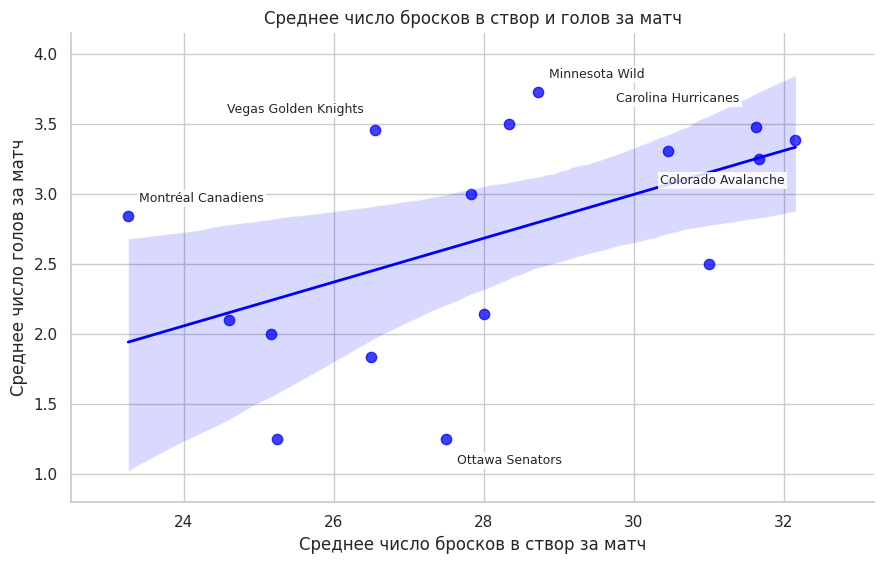

In [32]:
fig, ax = plt.subplots(figsize=(9, 5.8))

sns.regplot(
    data=avgshots,
    x="Shot",
    y="Goal",
    ci=95,
    seed=42,
    color="blue",
    scatter_kws={"s": 55, "alpha": 0.75},
    line_kws={"color": "blue", "linewidth": 2},
    ax=ax,
)

label_positions = {
    "Carolina Hurricanes": (-12, 18, "right"),
    "Colorado Avalanche": (-8, -32, "right"),
    "Minnesota Wild": (8, 10, "left"),
    "Montréal Canadiens": (8, 10, "left"),
    "Ottawa Senators": (8, -18, "left"),
    "Vegas Golden Knights": (-8, 12, "right"),
}

for team, (dx, dy, alignment) in label_positions.items():
    ax.annotate(
        team,
        xy=(avgshots.loc[team, "Shot"], avgshots.loc[team, "Goal"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha=alignment,
        fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5},
    )

ax.set_title("Среднее число бросков в створ и голов за матч")
ax.set_xlabel("Среднее число бросков в створ за матч")
ax.set_ylabel("Среднее число голов за матч")
ax.set_xlim(22.5, 33.2)
ax.set_ylim(0.8, 4.15)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

In [33]:
shot_goal_corr = avgshots["Shot"].corr(avgshots["Goal"])
round(shot_goal_corr, 3)

np.float64(0.521)

Видна **умеренная положительная связь**; корреляция равна примерно **0,521**. В среднем больше бросков связано с большим числом голов, но разброс довольно велик.

Например, Vegas Golden Knights забивали **3,455 гола** при **26,545 броска** в створ, а Dallas Stars — **2,500 гола** при **31,000 броска**. Одного объёма бросков для объяснения результативности недостаточно. Причинную связь по этой диаграмме также установить нельзя.

# Пункт 14

Найдём матч с наибольшим числом бросковых попыток. Здесь нужно включить и `blocked-shot`, поэтому вернёмся к `events`, а не к выборке из пункта 8. Посчитаем все четыре типа бросков по матчам и возьмём максимум.

In [34]:
all_shot_types = ["goal", "shot-on-goal", "blocked-shot", "missed-shot"]
shot_attempts = events.loc[events["Play Type"].isin(all_shot_types)].copy()

shot_counts = shot_attempts.groupby("Game ID").size().rename("Shot Count")
idxmax = shot_counts.idxmax()

gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

In [35]:
shot_counts.loc[idxmax]

np.int64(208)

In [36]:
shot_attempts.loc[shot_attempts["Game ID"] == idxmax, "Play Type"].value_counts().reindex(all_shot_types)

Play Type
goal             5
shot-on-goal    83
blocked-shot    54
missed-shot     66
Name: count, dtype: int64

Это матч **Carolina Hurricanes — Ottawa Senators, 20 апреля 2026 года**, завершившийся со счётом **3:2 во втором овертайме**. Всего было **208 попыток**: 5 голов, 83 броска, остановленных вратарём, 54 блока и 66 промахов. В створ пришлось 88 бросков с учётом голов. При сравнении с другими матчами важно помнить, что эта игра продолжалась пять периодов.

# Пункт 15

Нарисуем все броски найденного матча на площадке из `rink.py`. Цветом обозначим исход, треугольным маркером — команду.

Приведём атаки к одному направлению: хозяева Carolina Hurricanes бросают вправо, гости Ottawa Senators — влево. Для этого в нечётных периодах меняем знак обеих координат: `(x, y) → (-x, -y)`. Сохраним координаты рисунка в отдельных столбцах, чтобы не менять исходные данные.

In [37]:
match_attempts = shot_attempts.loc[shot_attempts["Game ID"] == idxmax].copy()

match_attempts["Plot X"] = match_attempts["X Coordinate on the Ice Rink"]
match_attempts["Plot Y"] = match_attempts["Y Coordinate on the Ice Rink"]

odd_periods = match_attempts["Period"] % 2 == 1
match_attempts.loc[odd_periods, ["Plot X", "Plot Y"]] = (
    -match_attempts.loc[odd_periods, ["Plot X", "Plot Y"]]
)

home_team = games.loc[idxmax, "Home Team"]
away_team = games.loc[idxmax, "Away Team"]

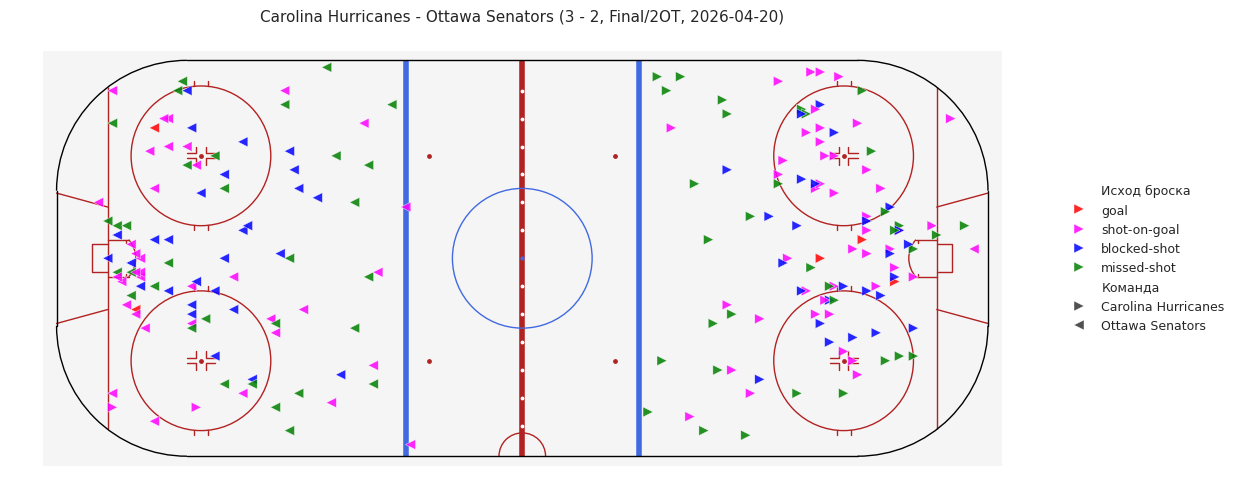

In [38]:
fig, ax = plt.subplots(figsize=(12.5, 5.3))
plot_rink(annotations=False)

sns.scatterplot(
    data=match_attempts,
    x="Plot X",
    y="Plot Y",
    hue="Play Type",
    hue_order=all_shot_types,
    palette={
        "goal": "red",
        "shot-on-goal": "magenta",
        "blocked-shot": "blue",
        "missed-shot": "green",
    },
    style="Team Making the Play",
    style_order=[home_team, away_team],
    markers={home_team: ">", away_team: "<"},
    s=52,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.35,
    zorder=3,
    ax=ax,
)

handles, labels = ax.get_legend_handles_labels()
legend_headers = {"Play Type": "Исход броска", "Team Making the Play": "Команда"}
labels = [legend_headers.get(label, label) for label in labels]
ax.legend(handles, labels, bbox_to_anchor=(1.02, 0.5), loc="center left",
          frameon=False, fontsize=9)

ax.set_title(gameInfo(idxmax), fontsize=11, pad=14)
ax.set_aspect("equal")
ax.axis("off")
fig.tight_layout()
plt.show()

Основная масса попыток находится рядом с атакуемыми воротами. Есть и дальние броски, в том числе с противоположной половины площадки. На рисунке показаны все **208 записей**, хотя некоторые точки могут перекрываться.

# Пункт 16

Посчитаем голы каждого игрока. Для событий `goal` автор гола записан в `Player in the Event #1`; остаётся подсчитать, сколько раз встречается каждое имя.

Небольшую функцию `top10()` будем использовать и дальше. Она сортирует игроков по показателю и оставляет десять строк. При равенстве значений ставим имена по алфавиту — это даёт однозначный порядок.

In [39]:
def top10(values, column_name):
    table = values.rename_axis("Player").reset_index(name=column_name)
    return (
        table.sort_values([column_name, "Player"], ascending=[False, True])
        .set_index("Player")
        .head(10)
    )

goal_events = events.loc[events["Play Type"] == "goal"].copy()
player_goals = goal_events["Player in the Event #1"].value_counts()
top_goal_scorers = top10(player_goals, "Goals")

top_goal_scorers

,Goals
Player,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Alex Newhook,7
Jackson Blake,7
Mark Stone,7


Больше всего голов у **Brett Howden — 14**, затем идут **Pavel Dorofeyev — 12** и **Logan Stankoven — 11**. На границе первой десятки есть игроки с одинаковым результатом: их порядок определён алфавитной сортировкой.

# Пункт 17

У одного гола может быть до двух авторов передач. Они записаны в полях `Player in the Event #2` и `Player in the Event #3`. Объединим оба столбца и посчитаем передачи; пустые ячейки в подсчёт не попадут.

In [40]:
assist_players = pd.concat([
    goal_events["Player in the Event #2"],
    goal_events["Player in the Event #3"],
])

player_assists = assist_players.value_counts()
top_assist_players = top10(player_assists, "Assists")

top_assist_players

,Assists
Player,
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Taylor Hall,12
Kirill Kaprizov,11


Лидируют **Jack Eichel с 20 передачами** и **Mitch Marner с 19**. Обе передачи при голе учитываются одинаково: каждая приносит игроку одно очко.

# Пункт 18

Сложим голы и передачи. Если игрок есть только в одном из двух списков, во втором показателе у него будет ноль. Выведем не только очки, но и их составляющие, чтобы результат было легко проверить.

In [41]:
player_stats = pd.DataFrame({
    "Goals": player_goals,
    "Assists": player_assists,
}).fillna(0).astype(int)

player_stats["Points"] = player_stats["Goals"] + player_stats["Assists"]
points_order = top10(player_stats["Points"], "Points").index
top_points_players = player_stats.loc[points_order]

top_points_players

,Goals,Assists,Points
Player,,,
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Lane Hutson,3,13,16
Logan Stankoven,11,5,16


По сумме гола и паса первым стал **Mitch Marner — 29 очков: 10 голов и 19 передач**. У Jack Eichel **22 очка**, у Jackson Blake — **20**.

# Пункт 19

Для среднего числа бросков нужно знать все матчи игрока, а не только те, где он бросал по воротам. Соберём пары «игрок — матч» из составов на льду, удалим повторы и посчитаем число игр.

В число бросков в створ включим `shot-on-goal` и `goal`, затем разделим их сумму на число сыгранных матчей. В таблице оставим оба исходных числа рядом со средним.

In [42]:
appearance_parts = []

for side in ["Away", "Home"]:
    lineup_columns = [
        f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)
    ] + [f"{side} Team's Goalie"]

    appearances = events[["Game ID"] + lineup_columns].melt(
        id_vars="Game ID", value_name="Player"
    ).dropna(subset=["Player"])
    appearance_parts.append(appearances[["Game ID", "Player"]])

player_games = pd.concat(appearance_parts, ignore_index=True).drop_duplicates()
games_played = player_games.groupby("Player")["Game ID"].nunique()

player_shots = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal"]),
    "Player in the Event #1",
].value_counts()

player_shot_stats = pd.DataFrame({
    "Games": games_played,
    "Shots": player_shots,
}).fillna({"Shots": 0})
player_shot_stats[["Games", "Shots"]] = player_shot_stats[["Games", "Shots"]].astype(int)
player_shot_stats["Shots per Game"] = player_shot_stats["Shots"] / player_shot_stats["Games"]

shot_order = top10(player_shot_stats["Shots per Game"], "Shots per Game").index
top_shots_players = player_shot_stats.loc[shot_order]
top_shots_players.round(3)

,Games,Shots,Shots per Game
Player,,,
Jason Robertson,6,30,5.000
Dylan Guenther,6,27,4.500
Nikita Kucherov,7,31,4.429
Matt Boldy,11,48,4.364
Quinton Byfield,4,17,4.250
Darren Raddysh,7,28,4.000
Joel Eriksson Ek,6,24,4.000
Alex Laferriere,4,15,3.750
David Pastrnak,6,22,3.667


Больше всех в среднем бросал **Jason Robertson: 30 бросков за 6 матчей, или 5 за игру**. Далее идут Dylan Guenther с **4,5** и Nikita Kucherov примерно с **4,429**. Результат зависит и от числа сыгранных матчей, поэтому этот столбец важен при сравнении.

# Пункт 20

Аналогично посчитаем силовые приёмы за матч. Для события `hit` нужный игрок указан в `Player in the Event #1`; второй участник — тот, против кого провели приём. Число игр берём из предыдущего пункта, включая матчи без силовых приёмов.

In [43]:
player_hits = events.loc[
    events["Play Type"] == "hit", "Player in the Event #1"
].value_counts()

player_hit_stats = pd.DataFrame({
    "Games": games_played,
    "Hits": player_hits,
}).fillna({"Hits": 0})
player_hit_stats[["Games", "Hits"]] = player_hit_stats[["Games", "Hits"]].astype(int)
player_hit_stats["Hits per Game"] = player_hit_stats["Hits"] / player_hit_stats["Games"]

hit_order = top10(player_hit_stats["Hits per Game"], "Hits per Game").index
top_hit_players = player_hit_stats.loc[hit_order]
top_hit_players.round(3)

,Games,Hits,Hits per Game
Player,,,
Lawson Crouse,6,38,6.333
Alex Turcotte,1,6,6.000
Alexander Petrovic,1,6,6.000
Yakov Trenin,9,51,5.667
Dylan Cozens,4,22,5.500
Vasily Podkolzin,6,32,5.333
Carl Grundstrom,3,15,5.000
Ivan Barbashev,22,110,5.000
Marcus Foligno,11,55,5.000


Первым оказался **Lawson Crouse — 38 приёмов за 6 матчей, в среднем 6,333**. У Alex Turcotte и Alexander Petrovic по 6 приёмов, но каждый сыграл лишь один матч. Минимальное число игр в условии не задано, поэтому они тоже включены в рейтинг.

# Пункт 21

Найдём вратарей, которые хотя бы в одном матче не пропустили за время своего участия. Счёта команды здесь недостаточно: один вратарь мог пропустить, а сменивший его — отыграть без голов.

В данных есть важная особенность. У **22 победных голов в овертаймах** одновременно пусты составы обеих команд и число игроков равно нулю. Это пропуск записи состава, а не свидетельство игры без вратарей. Если просто отбросить такие строки, например, Arturs Silovs и Jakub Dobes ошибочно попадут в список после поражений 0:1.

Для этих 22 голов возьмём вратарей из последнего события с заполненным составом **в том же матче и периоде**. Здесь делаем явное допущение, что до гола вратарь не сменился. Настоящие пропуски поля вратаря при записанном составе не заполняем. Поправку внесём в отдельную копию данных.

In [44]:
goalie_data = events.copy()

missing_lineup = (
    events[all_lineup_columns].isna().all(axis=1)
    & (events["# of Away Team's Players on the Ice"] == 0)
    & (events["# of Home Team's Players on the Ice"] == 0)
)

last_lineup_row = pd.Series(events.index, index=events.index).where(~missing_lineup)
last_lineup_row = last_lineup_row.groupby([events["Game ID"], events["Period"]]).ffill()
restore_goal = missing_lineup & (events["Play Type"] == "goal")

for side in ["Away", "Home"]:
    goalie_column = f"{side} Team's Goalie"
    goalie_data.loc[restore_goal, goalie_column] = (
        last_lineup_row.loc[restore_goal].map(events[goalie_column])
    )

goalie_data.loc[
    restore_goal,
    ["Game ID", "Period", "Away Team's Goalie", "Home Team's Goalie"],
].head()

,Game ID,Period,Away Team's Goalie,Home Team's Goalie
1853,2025030115,4,Jeremy Swayman,Alex Lyon
2548,2025030121,4,Jakub Dobes,Andrei Vasilevskiy
2977,2025030122,4,Jakub Dobes,Andrei Vasilevskiy
3296,2025030123,4,Andrei Vasilevskiy,Jakub Dobes
4351,2025030126,4,Andrei Vasilevskiy,Jakub Dobes


Теперь соберём все пары «вратарь — матч» и посчитаем голы соперника, когда этот вратарь указан на льду. В строках без голов поставим ноль. Голы при пустом поле защищающегося вратаря конкретному вратарю не приписываем.

In [45]:
goalie_appearances_parts = []
conceded_parts = []
fixed_goal_events = goalie_data.loc[goalie_data["Play Type"] == "goal"]

for side, opponent in [("Away", "Home"), ("Home", "Away")]:
    columns = ["Game ID", f"{side} Team", f"{side} Team's Goalie"]
    names = {f"{side} Team": "Team", f"{side} Team's Goalie": "Goalie"}

    goalie_appearances_parts.append(goalie_data[columns].rename(columns=names))
    conceded_parts.append(
        fixed_goal_events.loc[
            fixed_goal_events["Team Making the Play"] == fixed_goal_events[f"{opponent} Team"],
            columns,
        ].rename(columns=names)
    )

goalie_appearances = (
    pd.concat(goalie_appearances_parts, ignore_index=True)
    .dropna(subset=["Goalie"])
    .drop_duplicates()
)
conceded_goals = pd.concat(conceded_parts, ignore_index=True)
goals_against = (
    conceded_goals.dropna(subset=["Goalie"])
    .groupby(["Game ID", "Team", "Goalie"])
    .size()
    .rename("Goals Against")
)

goalie_games = (
    goalie_appearances.set_index(["Game ID", "Team", "Goalie"])
    .join(goals_against)
    .fillna({"Goals Against": 0})
)
goalie_games["Goals Against"] = goalie_games["Goals Against"].astype(int)

no_goals_games = goalie_games.loc[goalie_games["Goals Against"] == 0].reset_index()
goalies_no_goals = sorted(no_goals_games["Goalie"].unique().tolist())

goalies_no_goals

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Покажем и матчи, на основании которых вратари попали в список. Так можно проверить не только итоговые имена, но и случаи с заменами.

In [46]:
goalie_check = no_goals_games.copy()
goalie_check["Game Info"] = goalie_check["Game ID"].map(gameInfo)
goalie_check = goalie_check.sort_values(["Goalie", "Game ID"])

goalie_check[["Goalie", "Game ID", "Team", "Goals Against", "Game Info"]]

,Goalie,Game ID,Team,Goals Against,Game Info
0,Andrei Vasilevskiy,2025030126,Tampa Bay Lightning,0,Montréal Canadiens - Tampa Bay Lightning (0 - ...
3,Brandon Bussi,2025030416,Carolina Hurricanes,0,Vegas Golden Knights - Carolina Hurricanes (0 ...
1,Dan Vladar,2025030142,Philadelphia Flyers,0,Pittsburgh Penguins - Philadelphia Flyers (0 -...
6,Dan Vladar,2025030146,Philadelphia Flyers,0,Philadelphia Flyers - Pittsburgh Penguins (1 -...
5,Frederik Andersen,2025030131,Carolina Hurricanes,0,"Carolina Hurricanes - Ottawa Senators (2 - 0, ..."
7,Frederik Andersen,2025030221,Carolina Hurricanes,0,Carolina Hurricanes - Philadelphia Flyers (3 -...
2,Frederik Andersen,2025030314,Carolina Hurricanes,0,Montréal Canadiens - Carolina Hurricanes (0 - ...
4,Joonas Korpisalo,2025030114,Boston Bruins,0,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ..."
8,Scott Wedgewood,2025030235,Colorado Avalanche,0,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi..."


С учётом описанной поправки получилось **шесть вратарей**: Andrei Vasilevskiy, Brandon Bussi, Dan Vladar, Frederik Andersen, Joonas Korpisalo и Scott Wedgewood.

У них **девять подходящих сочетаний «вратарь — матч»**. Список включает и заменявших партнёров: например, Joonas Korpisalo не пропустил в матче, где Boston Bruins в целом пропустили шесть шайб. Итог зависит от принятого способа восстановления состава на решающих голах; это допущение показано выше.

# Пункт 22

**Чаще ли побеждала команда, которая нанесла больше бросков в створ?**

Для каждого матча сопоставим броски в створ и итоговый счёт обеих команд. Сначала отделим игры с равным числом бросков: в них нет команды с преимуществом по этому показателю. В остальных проверим, совпадает ли лидер по броскам с победителем.

In [47]:
shot_comparison = games[["Home Team", "Away Team", "Home Score", "Away Score"]].copy()
shot_comparison["Home Shots"] = [
    numshots.loc[(game_id, row["Home Team"]), "Shots on Goal"]
    for game_id, row in games.iterrows()
]
shot_comparison["Away Shots"] = [
    numshots.loc[(game_id, row["Away Team"]), "Shots on Goal"]
    for game_id, row in games.iterrows()
]

shot_comparison["Equal Shots"] = shot_comparison["Home Shots"] == shot_comparison["Away Shots"]
home_win = shot_comparison["Home Score"] > shot_comparison["Away Score"]
shot_comparison["Winner Has More Shots"] = (
    ((shot_comparison["Home Shots"] > shot_comparison["Away Shots"]) & home_win)
    | ((shot_comparison["Away Shots"] > shot_comparison["Home Shots"]) & ~home_win)
)

unequal_shots = shot_comparison.loc[~shot_comparison["Equal Shots"]]
more_shots_win = int(unequal_shots["Winner Has More Shots"].sum())
more_shots_lose = len(unequal_shots) - more_shots_win

shot_advantage_summary = pd.DataFrame({
    "Матчей": [more_shots_win, more_shots_lose],
    "Доля": [more_shots_win / len(unequal_shots), more_shots_lose / len(unequal_shots)],
}, index=["Больше бросков у победителя", "Больше бросков у проигравшего"])

shot_advantage_summary.round(3)

,Матчей,Доля
Больше бросков у победителя,47,0.603
Больше бросков у проигравшего,31,0.397


В **4 матчах** бросков было поровну. Из оставшихся **78 игр** команда с большим числом бросков победила в **47 случаях (60,3%)** и проиграла в **31 случае (39,7%)**.

В этой выборке преимущество по броскам чаще сочеталось с победой, но далеко не гарантировало её. Кроме количества бросков важны их качество и игра вратарей. Обратное влияние тоже возможно: уже сложившийся счёт меняет поведение команд. Поэтому полученные 60,3% описывают наблюдаемые матчи, а не доказывают, что дополнительные броски сами по себе вызвали победу.

Таким образом, подробный отчёт:
